<a href="https://colab.research.google.com/github/iarapineda/Ciencia-y-anal-tica-de-datos-Sep2026/blob/main/Actividad7PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 7**
Análisis de Componentes Principales (PCA)

---

*   NOMBRES Y MATRÍCULAS:

Iara Pérez Pineda | A01705855


En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

1. Descarga el archivo: `automobile_dataset.csv` y guarda, en un dataframe (`cars_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Al revisar los primeros registros, notarás que la columna `normalized_losses` contiene el símbolo `?`. Esto sugiere que se utilizó para indicar valores faltantes. Identifica todas las columnas que presentan este símbolo.
* Sustituye el símbolo `?` por valores faltantes (`NaN`) y convierte las columnas al tipo de dato adecuado. Esto es necesario porque la presencia del símbolo pudo haber hecho que pandas las interpretara como object, aunque en realidad no lo fueran.

In [3]:

cars_df = pd.read_csv('automobile_dataset.csv')
print("Dimensiones del dataset:", cars_df.shape)

cars_df.info()
cars_df.head()


Dimensiones del dataset: (205, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int6

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


**Análisis inicial del conjunto de datos**

El conjunto de datos contiene 205 registros y 26 columnas relacionadas con las características técnicas y especificaciones de automóviles. Mediante el método `info()` se identificaron inicialmente 12 columnas de tipo numérico y 14 de tipo `object`. Sin embargo, algunas de estas últimas contienen valores numéricos representados como texto, por lo que será necesario revisar y corregir sus tipos de datos antes de continuar con el análisis.

In [4]:

interrogaciones = (cars_df == '?').sum()
interrogaciones[interrogaciones > 0]


,0
normalized_losses,41
bore,4
stroke,4
horsepower,2
peak_rpm,2


**Identificación de valores faltantes**

Se identificaron cinco columnas que contienen el símbolo `?`: `normalized_losses` (41 registros), `bore` (4), `stroke` (4), `horsepower` (2) y `peak_rpm` (2). En total, se encontraron 53 valores representados mediante este símbolo. Estos deberán convertirse a `NaN` para que pandas los reconozca correctamente como datos faltantes y permita realizar su posterior tratamiento.

In [5]:

cars_df = cars_df.replace('?', float('nan'))
columnas_numericas = ['normalized_losses', 'bore', 'stroke', 'horsepower', 'peak_rpm']

cars_df[columnas_numericas] = cars_df[columnas_numericas].apply(pd.to_numeric)
cars_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

**Limpieza y corrección de tipos de datos**

Se reemplazaron los símbolos `?` por valores faltantes (`NaN`) y se convirtieron a formato numérico las cinco columnas afectadas. Después de la limpieza, el conjunto de datos contiene 17 columnas numéricas y 9 categóricas. Los valores faltantes se conservaron sin imputar, ya que su tratamiento se realizará posteriormente durante la etapa de ingeniería de características.

# Análisis exploratorio de datos (univariado)

2. Antes de iniciar con el análisis univariado, verifica si hay registros duplicados e imprime el porcentaje de faltantes por columna.
* Obtén las estadísticas descriptivas, separado las numéricas (incluye asimetría y curtosis) y las categóricas (incluye tablas de frecuencias).
* Genera histogramas para las numéricas y diagramas de barras para las categóricas.

In [6]:

duplicados = cars_df.duplicated().sum()
print("Registros duplicados:", duplicados)

faltantes = (cars_df.isna().mean() * 100).round(2)
print("\nPorcentaje de valores faltantes por columna:")
print(faltantes.to_string())


Registros duplicados: 0

Porcentaje de valores faltantes por columna:
symboling             0.00
normalized_losses    20.00
make                  0.00
fuel_type             0.00
aspiration            0.00
num_doors             0.00
body_style            0.00
drive_wheels          0.00
engine_location       0.00
wheel_base            0.00
length                0.00
width                 0.00
height                0.00
curb_weight           0.00
engine_type           0.00
num_cylinders         0.00
engine_size           0.00
fuel_system           0.00
bore                  1.95
stroke                1.95
compression_ratio     0.00
horsepower            0.98
peak_rpm              0.98
city_mpg              0.00
highway_mpg           0.00
price                 0.00


**Análisis de duplicados y valores faltantes**

Se verificó que el conjunto de datos no contiene registros duplicados. Respecto a los valores faltantes, se identificaron cinco columnas afectadas: `normalized_losses` (20%), `bore` (1.95%), `stroke` (1.95%), `horsepower` (0.98%) y `peak_rpm` (0.98%). La variable `normalized_losses` presenta la mayor proporción de datos faltantes, mientras que las otras 21 columnas están completas. Estos valores se conservarán para su posterior tratamiento mediante técnicas de imputación.

In [7]:

numericas = cars_df.select_dtypes(include='number')

estadisticas = numericas.describe().T
estadisticas['asimetria'] = numericas.skew()
estadisticas['curtosis'] = numericas.kurt()

display(estadisticas.round(2))


,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
symboling,205.0,0.83,1.25,-2.00,0.00,1.00,2.00,3.00,0.21,-0.68
normalized_losses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00,0.77,0.53
wheel_base,205.0,98.76,6.02,86.60,94.50,97.00,102.40,120.90,1.05,1.02
length,205.0,174.05,12.34,141.10,166.30,173.20,183.10,208.10,0.16,-0.08
width,205.0,65.91,2.15,60.30,64.10,65.50,66.90,72.30,0.90,0.70
height,205.0,53.72,2.44,47.80,52.00,54.10,55.50,59.80,0.06,-0.44
curb_weight,205.0,2555.57,520.68,1488.00,2145.00,2414.00,2935.00,4066.00,0.68,-0.04
num_cylinders,205.0,4.38,1.08,2.00,4.00,4.00,4.00,12.00,2.82,13.71
engine_size,205.0,126.91,41.64,61.00,97.00,120.00,141.00,326.00,1.95,5.31
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94,0.02,-0.83


**Análisis descriptivo de variables numéricas**

Las estadísticas descriptivas muestran diferencias en la distribución de las características de los automóviles. La variable `price` presenta un promedio de $13,150.31 y una mediana de $10,295, lo que refleja una asimetría positiva (1.84) asociada con vehículos de precios elevados. Asimismo, `num_cylinders`, `compression_ratio` y `engine_size` presentan asimetrías positivas pronunciadas. Destaca `num_cylinders` por su elevada curtosis (13.71), que sugiere la presencia de valores extremos. Estos resultados permiten identificar distribuciones que requieren especial atención durante el análisis de los datos.

In [8]:

categoricas = cars_df.select_dtypes(include='object')

display(categoricas.describe().T)

for columna in categoricas.columns:
    print(f"\n{columna}")
    display(categoricas[columna].value_counts())


,count,unique,top,freq
make,205,22,toyota,32
fuel_type,205,2,gas,185
aspiration,205,2,std,168
num_doors,205,2,four,116
body_style,205,5,sedan,96
drive_wheels,205,3,fwd,120
engine_location,205,2,front,202
engine_type,205,7,ohc,148
fuel_system,205,8,mpfi,94



make


,count
make,
toyota,32
nissan,18
mazda,17
mitsubishi,13
honda,13
subaru,12
volkswagen,12
volvo,11
peugot,11



fuel_type


,count
fuel_type,
gas,185
diesel,20



aspiration


... (9 outputs left out)


engine_type


,count
engine_type,
ohc,148
ohcf,15
ohcv,13
dohc,12
l,12
rotor,4
dohcv,1



fuel_system


,count
fuel_system,
mpfi,94
2bbl,66
idi,20
1bbl,11
spdi,9
4bbl,3
mfi,1
spfi,1


**Análisis descriptivo de variables categóricas**

El análisis de frecuencias muestra que Toyota es el fabricante más representado, con 32 automóviles. Predominan los vehículos de gasolina (185), con aspiración estándar (168), carrocería sedán (96) y tracción delantera (120). Asimismo, la mayoría de los automóviles cuenta con motor delantero (202) y el tipo de motor más frecuente es `ohc` (148). Estos resultados permiten identificar las características predominantes dentro del conjunto de datos.

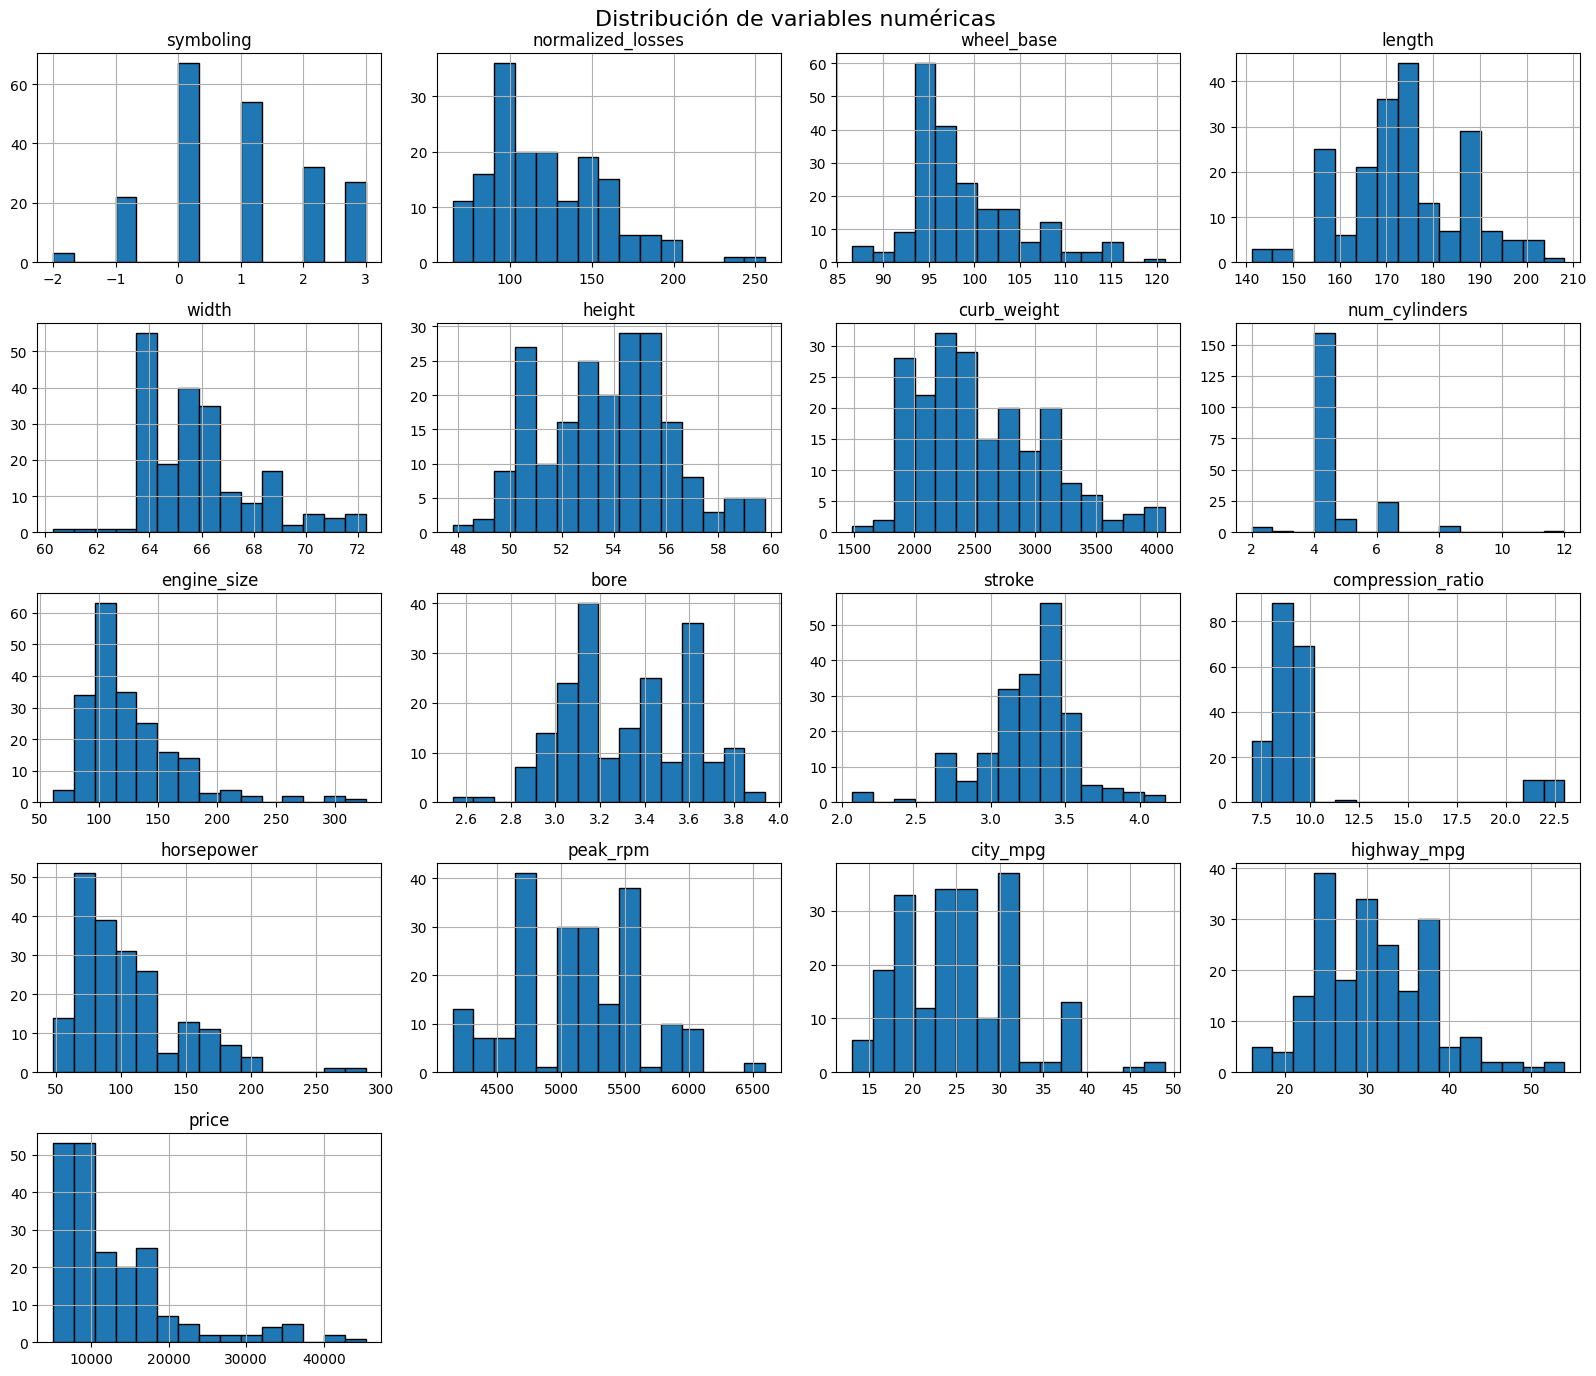

In [9]:

numericas.hist(figsize=(16, 14), bins=15, edgecolor='black')

plt.suptitle('Distribución de variables numéricas', fontsize=16)
plt.tight_layout()
plt.show()


**Análisis de histogramas**

Los histogramas muestran que variables como `price`, `engine_size` y `horsepower` presentan distribuciones asimétricas hacia la derecha, con una mayor concentración de automóviles en valores bajos y pocos registros con valores elevados. La variable `num_cylinders` se concentra principalmente en cuatro cilindros, mientras que `compression_ratio` presenta dos grupos de valores claramente diferenciados. En contraste, variables como `length` y `height` muestran distribuciones relativamente más equilibradas. Estas visualizaciones permiten identificar patrones de concentración, asimetría y posibles valores atípicos en las características de los automóviles.

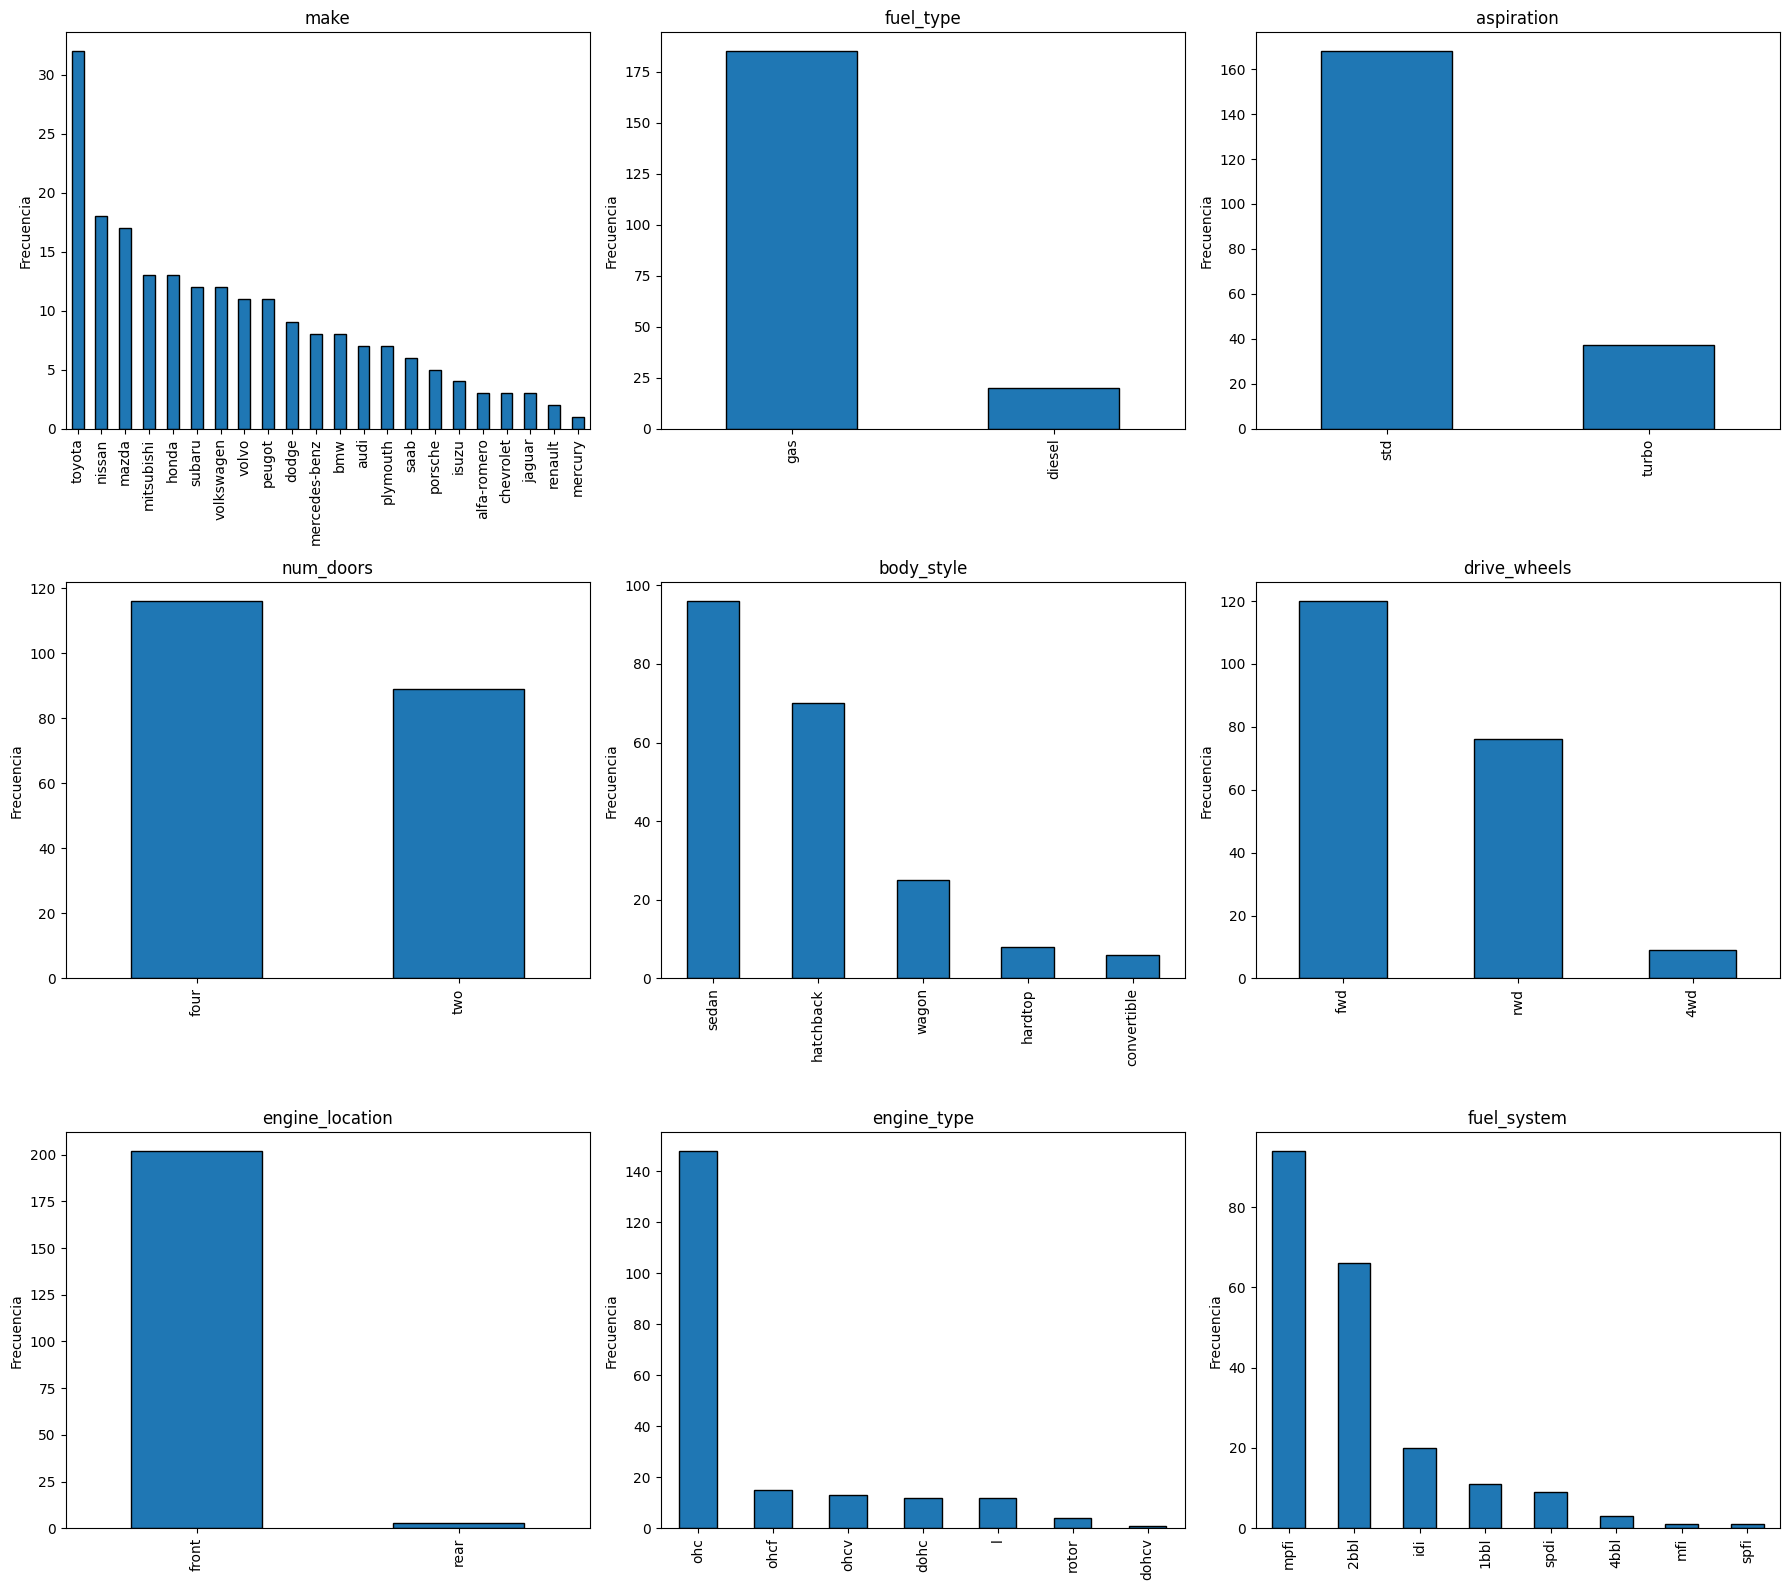

In [10]:

fig, axes = plt.subplots(3, 3, figsize=(18, 16))

for ax, columna in zip(axes.flat, categoricas.columns):
    categoricas[columna].value_counts().plot(kind='bar', ax=ax, edgecolor='black')
    ax.set_title(columna)
    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x', labelrotation=90)

plt.tight_layout()
plt.show()


**Análisis de diagramas de barras**

Los diagramas de barras muestran un predominio de automóviles Toyota (32 registros), seguidos de Nissan (18) y Mazda (17). La mayoría utiliza gasolina (185), aspiración estándar (168), carrocería sedán (96) y tracción delantera (120). También destaca la ubicación del motor en la parte delantera (202) y el uso de motores tipo `ohc` (148). En general, se observa una distribución desigual entre las categorías, con ciertas características ampliamente representadas y otras poco frecuentes.

# Análisis exploratorio de datos (bivariado)

3. Genera algunos gráficos bivariados para familiarizarte con el conjunto de datos:
* Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.
* Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería. Esto permitirá comparar la mediana, los cuartiles y la presencia de valores atípicos entre los diferentes tipos de carrocería.
* Gráfico de barras que muestre los 10 automóviles más caros, ordenados de mayor a menor precio, con cada barra diferenciada con color por fabricante.
* Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles. Diferencia con colores los puntos según el tipo de aspiración y con el tamaño de los puntos el número de puertas.

**Nota.** Debes incluir en cada gráfico una conclusión de lo observado.

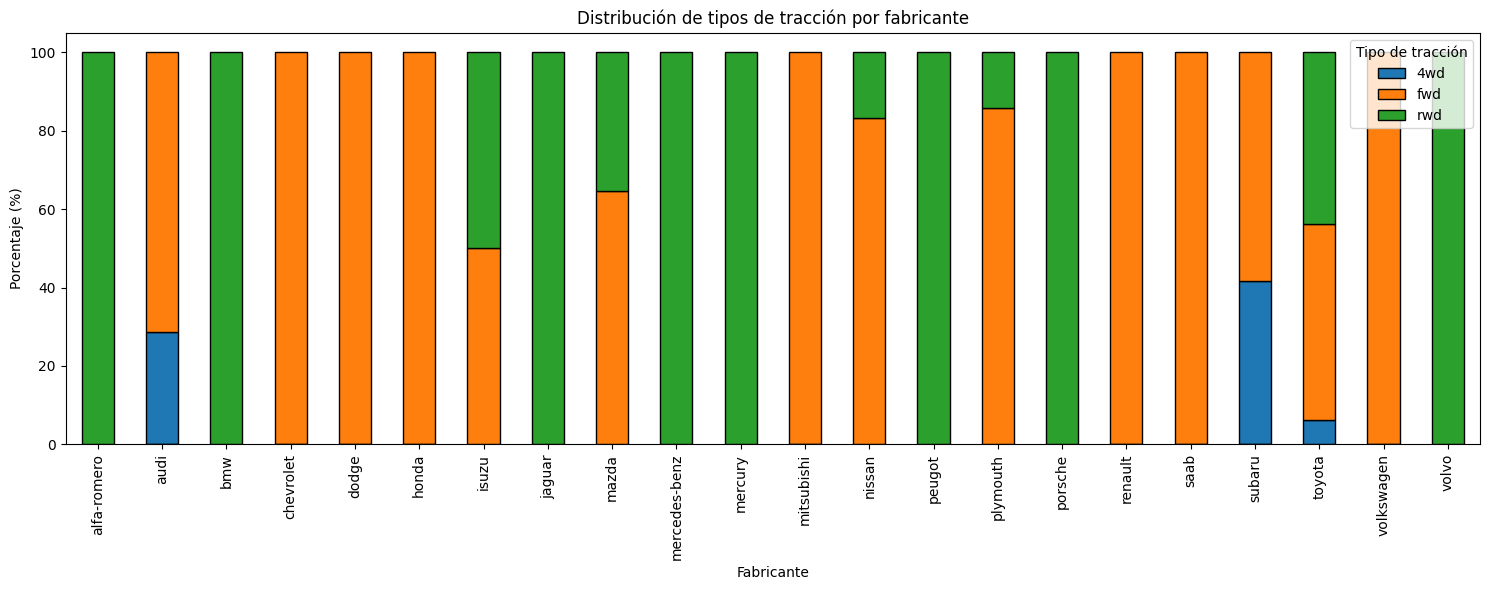

In [11]:

traccion = pd.crosstab(cars_df['make'], cars_df['drive_wheels'], normalize='index') * 100

traccion.plot(kind='bar', stacked=True, figsize=(15, 6), edgecolor='black')

plt.title('Distribución de tipos de tracción por fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Tipo de tracción')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


**Análisis de la distribución de tipos de tracción por fabricante**

El gráfico muestra que la distribución de los tipos de tracción varía según el fabricante. La tracción delantera (`fwd`) predomina en marcas como Chevrolet, Honda y Mitsubishi, mientras que BMW, Mercedes-Benz y Volvo presentan exclusivamente tracción trasera (`rwd`) dentro del conjunto de datos. Por otro lado, Subaru y Audi incluyen vehículos con tracción en las cuatro ruedas (`4wd`), y Toyota presenta los tres tipos de tracción. Estos resultados permiten identificar diferencias en las configuraciones mecánicas de los automóviles según su fabricante.

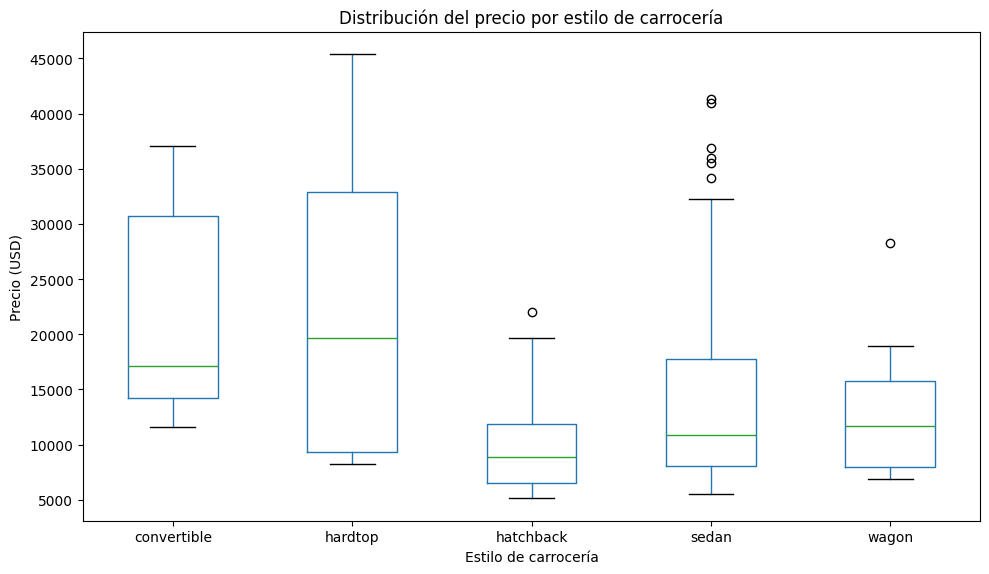

In [12]:

cars_df.boxplot(column='price', by='body_style', figsize=(10, 6), grid=False)

plt.suptitle('')
plt.title('Distribución del precio por estilo de carrocería')
plt.xlabel('Estilo de carrocería')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()


**Análisis de precios por estilo de carrocería**

El diagrama de cajas muestra que los automóviles de tipo `hardtop` y `convertible` presentan las medianas de precio más elevadas, mientras que los `hatchback` tienen la mediana más baja. Los vehículos `hardtop` también muestran una amplia dispersión de precios. Por otra parte, los `sedan` presentan varios valores atípicos de precios elevados, algunos superiores a $40,000 USD. Estos resultados indican que el precio y su variabilidad difieren según el estilo de carrocería.

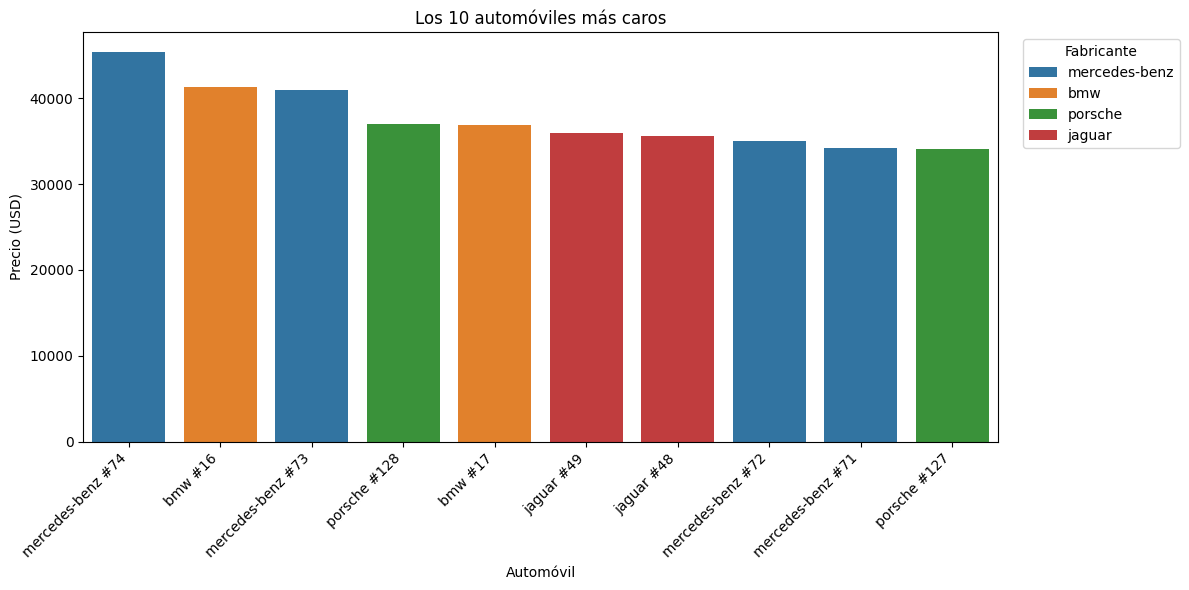

In [13]:

top_10 = cars_df.nlargest(10, 'price').copy()

top_10['automovil'] = top_10['make'] + ' #' + top_10.index.astype(str)

plt.figure(figsize=(12, 6))

sns.barplot(data=top_10, x='automovil', y='price', hue='make', dodge=False)

plt.title('Los 10 automóviles más caros')
plt.xlabel('Automóvil')
plt.ylabel('Precio (USD)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Fabricante', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Análisis de los 10 automóviles más caros**

El gráfico muestra que Mercedes-Benz tiene el automóvil más caro del conjunto de datos con un precio de 45,400 USD, seguido de BMW con aproximadamente $41,300. Entre los diez vehículos de mayor precio predominan cuatro fabricantes: Mercedes-Benz, BMW, Porsche y Jaguar. Destaca Mercedes-Benz con cuatro registros, mientras que los otros fabricantes aparecen dos veces cada uno. Estos resultados permiten identificar las marcas que concentran los precios más elevados dentro del conjunto de datos.

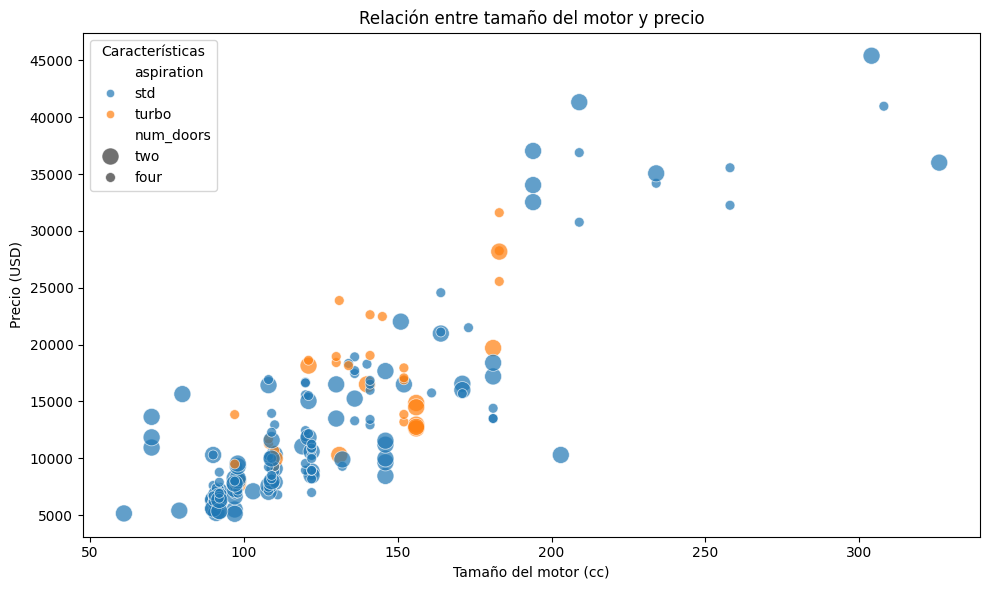

In [14]:

plt.figure(figsize=(10, 6))

sns.scatterplot(data=cars_df, x='engine_size', y='price',
                hue='aspiration', size='num_doors',
                sizes=(50, 150), alpha=0.7)

plt.title('Relación entre tamaño del motor y precio')
plt.xlabel('Tamaño del motor (cc)')
plt.ylabel('Precio (USD)')
plt.legend(title='Características')
plt.tight_layout()
plt.show()


**Análisis de la relación entre tamaño del motor y precio**

El diagrama de dispersión muestra una relación positiva entre el tamaño del motor (`engine_size`) y el precio (`price`), ya que los automóviles con motores más grandes tienden a presentar precios más elevados. Los vehículos con aspiración estándar abarcan un rango más amplio de tamaños y precios, mientras que los modelos turbo se concentran principalmente en valores intermedios. Respecto al número de puertas, no se observa una diferencia clara en la distribución de precios. En general, el tamaño del motor parece estar relacionado con el precio de los automóviles.

4. Genera un mapa de calor de la matriz de correlación entre las variables numéricas del conjunto de datos, mostrando los valores de correlación en cada celda.
* ¿Cuáles son las tres variables más correlacionadas con el precio?

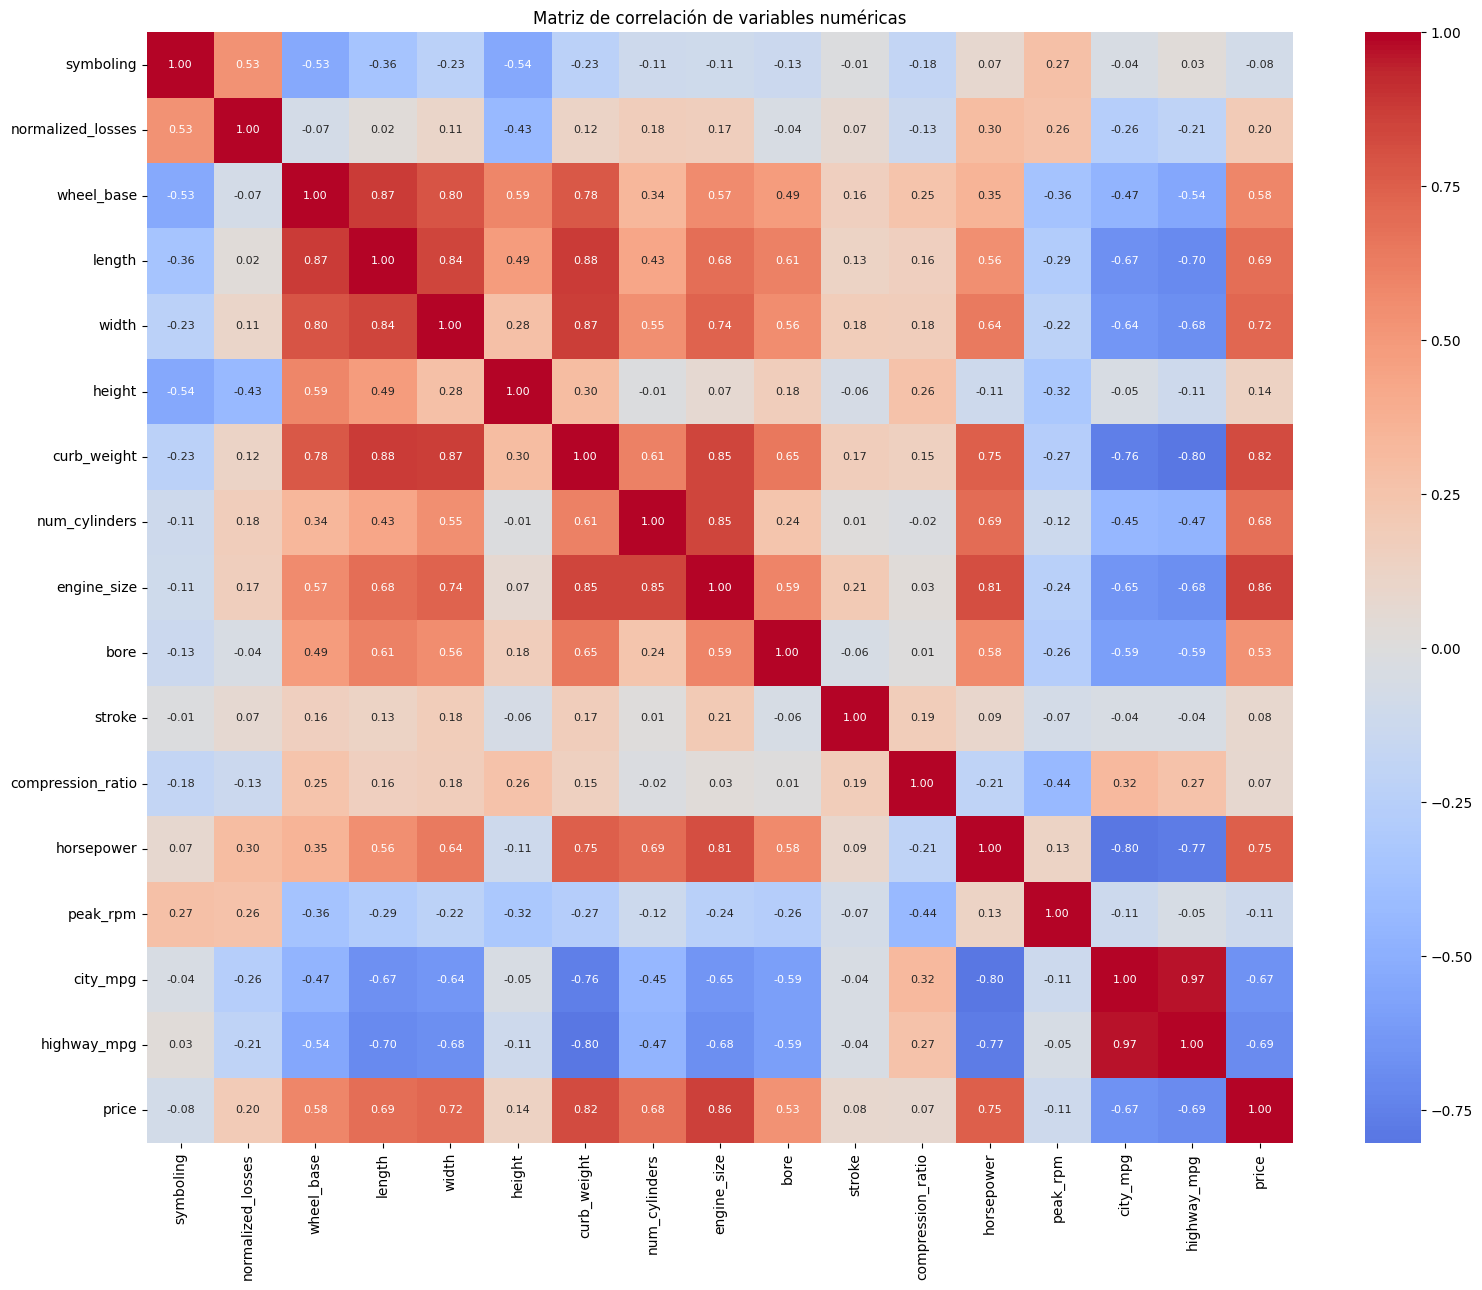

In [15]:

correlacion = numericas.corr()

plt.figure(figsize=(16, 13))

sns.heatmap(correlacion, annot=True, fmt='.2f',
            cmap='coolwarm', center=0,
            annot_kws={'size': 8})

plt.title('Matriz de correlación de variables numéricas')
plt.tight_layout()
plt.show()


In [16]:

correlaciones_precio = correlacion['price'].drop('price')

top_3 = correlaciones_precio.loc[
    correlaciones_precio.abs().nlargest(3).index
]

display(top_3)


,price
engine_size,0.860343
curb_weight,0.819817
horsepower,0.749844


**Análisis de la matriz de correlación**

La matriz de correlación muestra que las tres variables más relacionadas con el precio (`price`) son `engine_size` (r = 0.8603), `curb_weight` (r = 0.8198) y `horsepower` (r = 0.7498). Todas presentan correlaciones positivas fuertes, lo que indica que los automóviles con motores más grandes, mayor peso y mayor potencia tienden a tener precios más elevados. Asimismo, se identifican correlaciones altas entre otras características, como `city_mpg` y `highway_mpg` (r = 0.97), lo que sugiere la presencia de información redundante. Estos resultados respaldan la aplicación posterior de PCA para reducir la dimensionalidad del conjunto de predictores.

# Ingeniería de características

5. Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
* Considera `price` como la variable objetivo y guárdala en `y`. Separa los predictores numéricos en `X`. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
* Aplica `SimpleImputer` sobre `X` para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
* Realiza el escalamiento del conjunto `X` ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.

PCA está diseñado principalmente para variables numéricas y funciona encontrando combinaciones lineales de las variables originales que capturan la mayor varianza en los datos. Normalmente se recomienda eliminar las variables categóricas antes de aplicar PCA y luego concatenarlas nuevamente con los resultados de PCA si se desea.

In [17]:

y = cars_df['price']
X = cars_df.select_dtypes(include='number').drop(columns='price')

print("Variables predictoras:", X.shape[1])
print("Componentes principales posibles:", X.shape[1])

X.head()


Variables predictoras: 16
Componentes principales posibles: 16


,symboling,normalized_losses,wheel_base,length,width,height,curb_weight,num_cylinders,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg
0,3,NaN,88.6,168.8,64.1,48.8,2548,4,130,3.47,2.68,9.0,111.0,5000.0,21,27
1,3,NaN,88.6,168.8,64.1,48.8,2548,4,130,3.47,2.68,9.0,111.0,5000.0,21,27
2,1,NaN,94.5,171.2,65.5,52.4,2823,6,152,2.68,3.47,9.0,154.0,5000.0,19,26
3,2,164.0,99.8,176.6,66.2,54.3,2337,4,109,3.19,3.40,10.0,102.0,5500.0,24,30
4,2,164.0,99.4,176.6,66.4,54.3,2824,5,136,3.19,3.40,8.0,115.0,5500.0,18,22


**Selección de variables para PCA**

Se separó la variable objetivo `price` en `y` y se seleccionaron las 16 variables numéricas restantes como predictores en `X`. Dado que PCA genera como máximo un componente principal por cada variable original, se podrán obtener 16 componentes. Posteriormente, se determinará cuántos conservar para representar la mayor parte de la variabilidad del conjunto de datos.

In [18]:

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_imputado = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Valores faltantes antes:", X.isna().sum().sum())
print("Valores faltantes después:", X_imputado.isna().sum().sum())

X_imputado.head()


Valores faltantes antes: 53
Valores faltantes después: 0


,symboling,normalized_losses,wheel_base,length,width,height,curb_weight,num_cylinders,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg
0,3.0,115.0,88.6,168.8,64.1,48.8,2548.0,4.0,130.0,3.47,2.68,9.0,111.0,5000.0,21.0,27.0
1,3.0,115.0,88.6,168.8,64.1,48.8,2548.0,4.0,130.0,3.47,2.68,9.0,111.0,5000.0,21.0,27.0
2,1.0,115.0,94.5,171.2,65.5,52.4,2823.0,6.0,152.0,2.68,3.47,9.0,154.0,5000.0,19.0,26.0
3,2.0,164.0,99.8,176.6,66.2,54.3,2337.0,4.0,109.0,3.19,3.40,10.0,102.0,5500.0,24.0,30.0
4,2.0,164.0,99.4,176.6,66.4,54.3,2824.0,5.0,136.0,3.19,3.40,8.0,115.0,5500.0,18.0,22.0


**Imputación de valores faltantes**

Se aplicó `SimpleImputer` utilizando la estrategia de la mediana para reemplazar los valores faltantes de las variables predictoras numéricas. Se seleccionó este método porque algunas variables presentan distribuciones asimétricas y posibles valores atípicos, ante los cuales la mediana es menos sensible que la media. Esta técnica permite conservar los registros originales sin alterar excesivamente la distribución de los datos.

In [19]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_escalado = pd.DataFrame(
    scaler.fit_transform(X_imputado),
    columns=X_imputado.columns,
    index=X_imputado.index
)

X_escalado.head()


,symboling,normalized_losses,wheel_base,length,width,height,curb_weight,num_cylinders,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg
0,1.743470,-0.176503,-1.690772,-0.426521,-0.844782,-2.020417,-0.014566,-0.352887,0.074449,0.520489,-1.841345,-0.288349,0.173309,-0.264983,-0.646553,-0.546059
1,1.743470,-0.176503,-1.690772,-0.426521,-0.844782,-2.020417,-0.014566,-0.352887,0.074449,0.520489,-1.841345,-0.288349,0.173309,-0.264983,-0.646553,-0.546059
2,0.133509,-0.176503,-0.708596,-0.231513,-0.190566,-0.543527,0.514882,1.502032,0.604046,-2.403313,0.683683,-0.288349,1.263761,-0.264983,-0.953012,-0.691627
3,0.938490,1.367901,0.173698,0.207256,0.136542,0.235942,-0.420797,-0.352887,-0.431076,-0.515795,0.459947,-0.035973,-0.054925,0.785723,-0.186865,-0.109354
4,0.938490,1.367901,0.107110,0.207256,0.230001,0.235942,0.516807,0.574572,0.218885,-0.515795,0.459947,-0.540725,0.274747,0.785723,-1.106241,-1.273900


**Escalamiento de variables numéricas**

Se aplicó `StandardScaler` a los 16 predictores numéricos previamente imputados, transformándolos mediante la estandarización Z-score. Este procedimiento permite que las variables tengan media cercana a cero y desviación estándar igual a uno, evitando que aquellas con mayores magnitudes dominen el análisis PCA. De esta manera, los componentes principales podrán calcularse considerando las variables en una escala comparable.

6. Aplica `PCA` a los datos escalados para proyectarlos en el nuevo espacio de vectores.
* Asigna nombres descriptivos a los componentes principales en el dataframe resultante, utilizando la convención PC1, PC2, PC3, y así sucesivamente.
* Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.

In [20]:

from sklearn.decomposition import PCA

pca = PCA()

componentes = pca.fit_transform(X_escalado)

pca_df = pd.DataFrame(
    componentes,
    columns=[f'PC{i+1}' for i in range(componentes.shape[1])],
    index=X_escalado.index
)

print("Dimensiones:", pca_df.shape)
pca_df.head()


Dimensiones: (205, 16)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,1.370499,-1.130802,-1.013703,0.502983,0.657052,0.174955,-0.008520,0.118635,-0.111688
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,0.400032,0.293338,0.168137,0.039239,-0.022832,-0.078891,-0.391786,0.009265,0.053641
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,0.870186,0.015429,-0.447054,-0.055376,-0.416053,-0.049431,0.079357,-0.198402,0.046303


**Aplicación del Análisis de Componentes Principales (PCA)**

Se aplicó PCA sobre las 16 variables numéricas previamente imputadas y estandarizadas. Como resultado, se obtuvo una nueva representación de las 205 observaciones mediante 16 componentes principales, denominados PC1, PC2, …, PC16. Estos componentes son combinaciones lineales de las variables originales y están ordenados según la cantidad de varianza que explican.

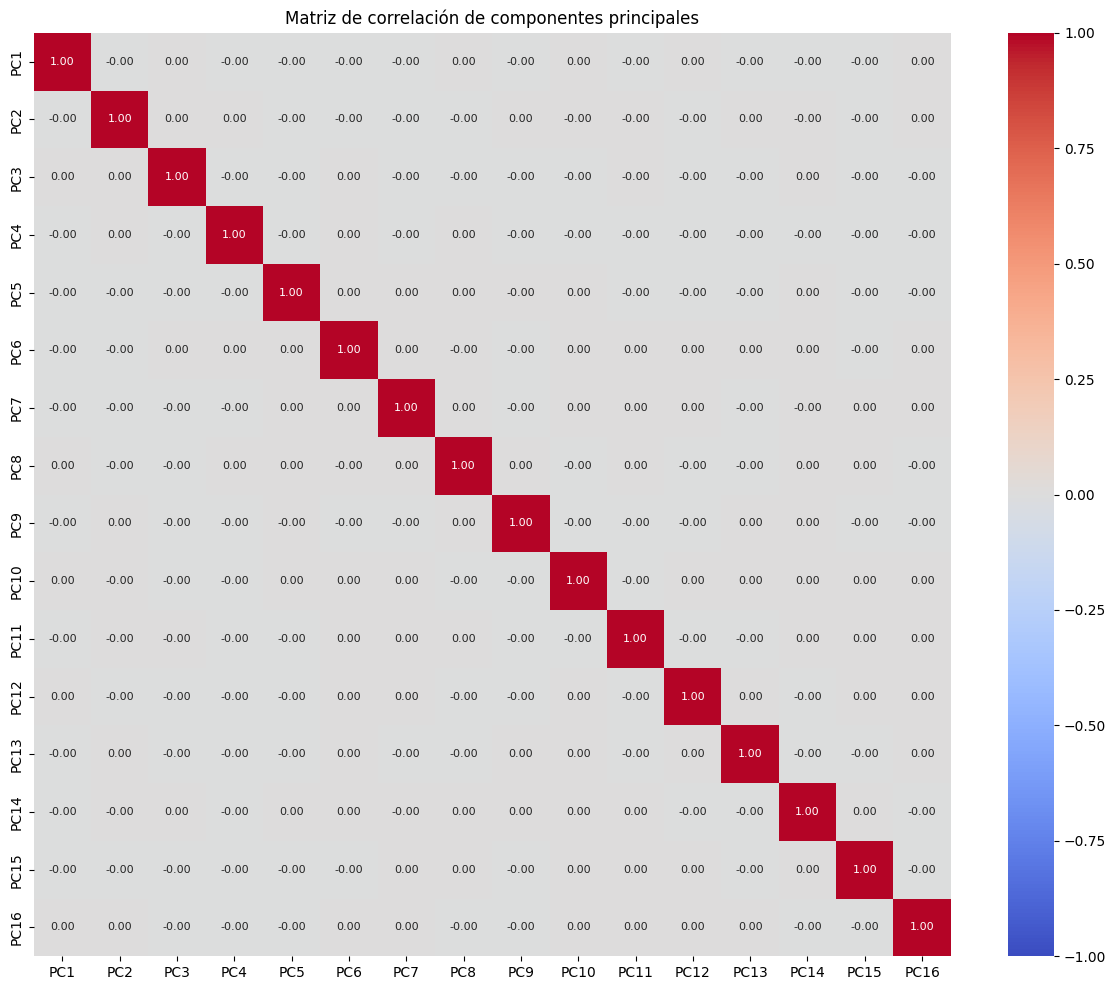

In [21]:

correlacion_pca = pca_df.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(correlacion_pca, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot_kws={'size': 8})

plt.title('Matriz de correlación de componentes principales')
plt.tight_layout()
plt.show()


**Análisis de correlación de los componentes principales**

El mapa de calor muestra correlaciones cercanas a cero entre los diferentes componentes principales, mientras que la diagonal presenta valores iguales a uno. Esto confirma que los componentes generados mediante PCA no están correlacionados linealmente entre sí, lo que permite representar la información original mediante nuevas variables sin redundancia lineal.

7. Obtén el porcentaje de varianza explicada por cada componente.
* Grafica la curva de varianza acumulada para determinar el número mínimo de componentes principales que explican más del 90% de la varianza total.

In [22]:

varianza = pd.DataFrame({
    'Componente': pca_df.columns,
    'Varianza explicada (%)': pca.explained_variance_ratio_ * 100,
    'Varianza acumulada (%)': pca.explained_variance_ratio_.cumsum() * 100
})

display(varianza.round(2))


,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,44.55,44.55
1,PC2,17.93,62.48
2,PC3,8.58,71.05
3,PC4,6.44,77.49
4,PC5,5.74,83.23
5,PC6,4.78,88.01
6,PC7,3.25,91.26
7,PC8,2.73,93.98
8,PC9,1.94,95.92
9,PC10,1.55,97.48


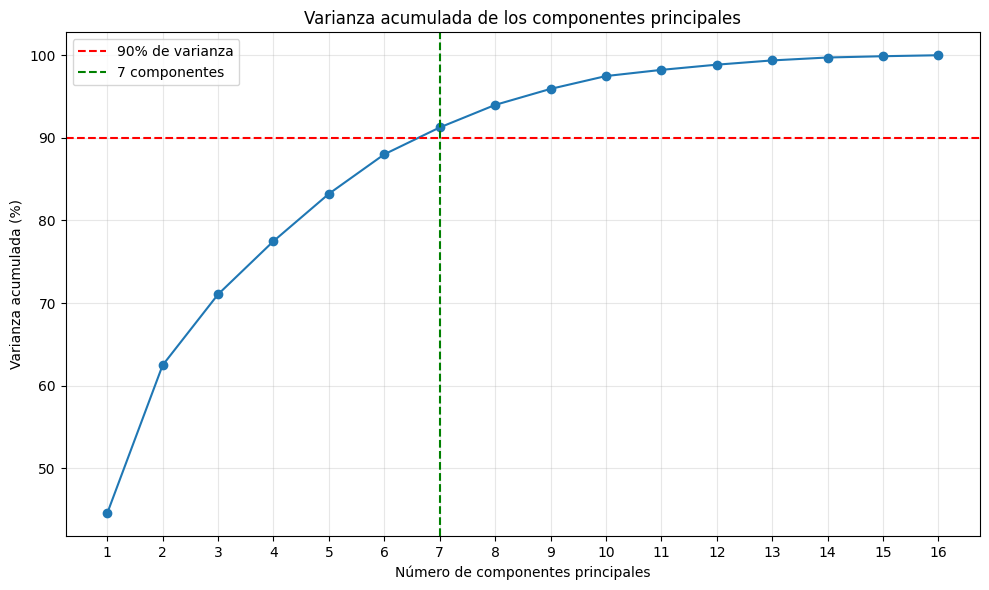

Componentes seleccionados: 7


In [23]:

n_componentes = (varianza['Varianza acumulada (%)'] <= 90).sum() + 1

plt.figure(figsize=(10, 6))

plt.plot(range(1, 17), varianza['Varianza acumulada (%)'], marker='o')

plt.axhline(y=90, color='red', linestyle='--', label='90% de varianza')
plt.axvline(x=n_componentes, color='green', linestyle='--', label=f'{n_componentes} componentes')

plt.title('Varianza acumulada de los componentes principales')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza acumulada (%)')
plt.xticks(range(1, 17))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Componentes seleccionados:", n_componentes)


**Análisis de varianza explicada y selección de componentes**

El análisis muestra que el primer componente principal (PC1) explica el 44.55% de la varianza total, mientras que los primeros dos componentes acumulan el 62.48%. Para superar el umbral del 90%, es necesario conservar los primeros siete componentes principales, que explican conjuntamente el 91.26% de la varianza. Esto permite reducir la dimensionalidad de 16 variables numéricas a 7 componentes, conservando la mayor parte de la variabilidad original y eliminando aproximadamente el 8.74% de la varianza.

8. Imprime la información de los componentes seleccionados (cargas o pesos de las variables originales) para interpretar qué variables contribuyen más a cada componente principal.
* Dibuja un diagrama de barras que muestre qué variables originales aportan más al primer componente principal (PC1), para visualizar su influencia relativa.

In [24]:

cargas = pd.DataFrame(
    pca.components_[:n_componentes].T,
    index=X.columns,
    columns=pca_df.columns[:n_componentes]
)

display(cargas.round(3))


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
symboling,-0.097,-0.403,0.265,-0.072,-0.366,0.173,0.128
normalized_losses,0.016,-0.331,0.308,-0.343,-0.376,-0.492,-0.323
wheel_base,0.298,0.265,-0.029,-0.228,-0.004,-0.183,-0.106
length,0.338,0.139,-0.044,-0.194,-0.074,-0.082,-0.009
width,0.334,0.055,0.109,-0.098,-0.016,-0.107,0.140
height,0.114,0.422,-0.282,-0.186,-0.017,-0.214,-0.003
curb_weight,0.362,0.022,0.080,-0.025,-0.042,-0.014,0.061
num_cylinders,0.245,-0.114,0.177,0.552,0.237,-0.354,-0.068
engine_size,0.330,-0.082,0.199,0.296,0.109,0.016,-0.073
bore,0.263,0.003,-0.138,0.041,-0.373,0.512,0.126


**Interpretación de los componentes principales**

Se analizaron los coeficientes de las 16 variables originales en los siete componentes seleccionados. En PC1 destacan `curb_weight` (0.362), `length` (0.338), `width` (0.334) y `engine_size` (0.330), mientras que `highway_mpg` (-0.317) y `city_mpg` (-0.306) presentan pesos negativos importantes. Esto indica que PC1 está relacionado principalmente con las dimensiones, el peso, el tamaño del motor y el rendimiento de combustible de los automóviles.

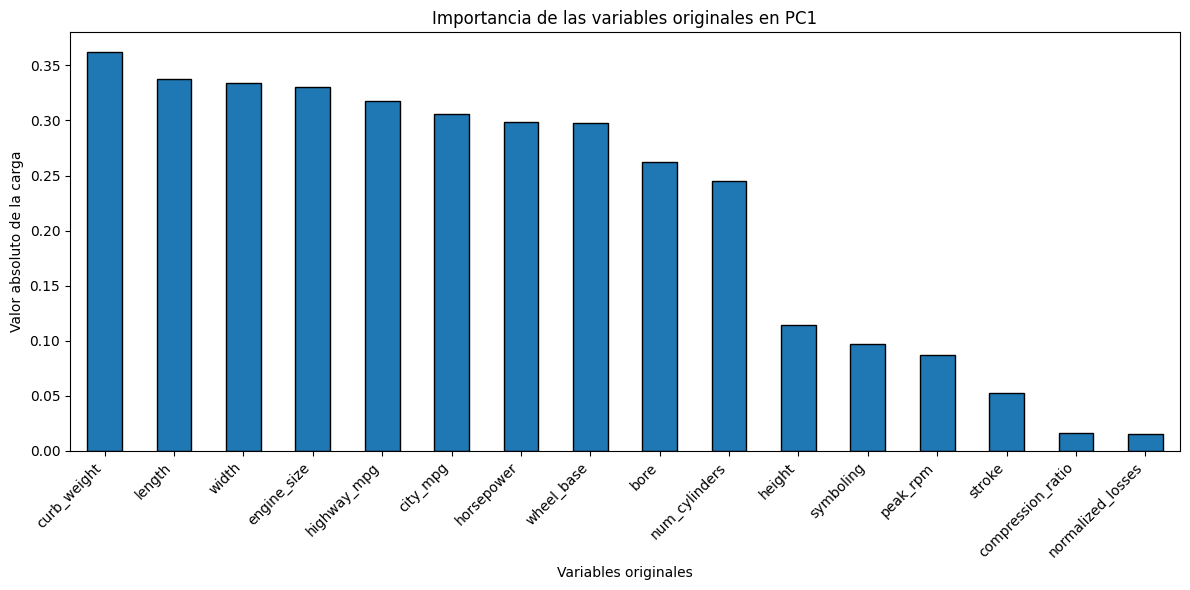

In [25]:

importancia_pc1 = cargas['PC1'].abs().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

importancia_pc1.plot(kind='bar', edgecolor='black')

plt.title('Importancia de las variables originales en PC1')
plt.xlabel('Variables originales')
plt.ylabel('Valor absoluto de la carga')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Análisis de la importancia de las variables en PC1**

El diagrama de barras muestra que las variables con mayor influencia en PC1 son `curb_weight`, `length`, `width` y `engine_size`, seguidas de `highway_mpg` y `city_mpg`. Esto indica que el primer componente resume principalmente características relacionadas con el tamaño, peso y rendimiento de combustible de los automóviles. Para comparar la magnitud de las cargas se utilizaron valores absolutos, considerando tanto los coeficientes positivos como los negativos.

9. Codifica las variables categóricas mediante *One-Hot Encoding* y utiliza el parámetro `drop='first'` para evitar problemas de multicolinealidad entre las variables dummy generadas.

In [26]:

from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False)

categoricas_codificadas = pd.DataFrame(
    encoder.fit_transform(categoricas),
    columns=encoder.get_feature_names_out(categoricas.columns),
    index=cars_df.index
)

print("Columnas originales:", categoricas.shape[1])
print("Columnas codificadas:", categoricas_codificadas.shape[1])

categoricas_codificadas.head()


Columnas originales: 9
Columnas codificadas: 44


,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,...,engine_type_ohcf,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


**Codificación de variables categóricas**

Se aplicó One-Hot Encoding a las nueve variables categóricas utilizando `drop='first'`. Esta técnica transforma las categorías en variables binarias y elimina una categoría de referencia por cada variable original, evitando redundancia entre las columnas dummy generadas. De esta manera, las características categóricas quedan representadas numéricamente y podrán integrarse con los componentes principales en el conjunto de datos final.

10. Conjunta, en un dataframe, las valores proyectados en los componentes seleccionados (mínimo), las transformaciones obtenidas de las variables categóricas y la variable de salida.
* Almacena el dataframe resultante en archivo.

In [27]:

cars_final = pd.concat([
    pca_df.iloc[:, :n_componentes],
    categoricas_codificadas,
    y
], axis=1)

print("Dimensiones del conjunto final:", cars_final.shape)
print("Valores faltantes:", cars_final.isna().sum().sum())

cars_final.head()


Dimensiones del conjunto final: (205, 52)
Valores faltantes: 0


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,make_audi,make_bmw,make_chevrolet,...,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi,price
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13495
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13950
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,17450


**Integración del conjunto de datos final**

Se integraron los siete componentes principales seleccionados, las 44 variables generadas mediante One-Hot Encoding y la variable objetivo `price` en un único dataframe. El conjunto resultante contiene 205 registros y 52 columnas, conservando el 91.26% de la varianza de los predictores numéricos originales mediante PCA. De esta manera, se obtiene un conjunto de datos preparado para su utilización en etapas posteriores de modelado.

In [28]:

cars_final.to_csv('automobile_pca_final.csv', index=False)

print("Archivo guardado: automobile_pca_final.csv")


Archivo guardado: automobile_pca_final.csv


**Exportación del conjunto de datos**

El conjunto de datos final se almacenó en el archivo `automobile_pca_final.csv`, conservando los 205 registros y las 52 columnas resultantes del procesamiento. El archivo contiene los componentes principales seleccionados, las variables categóricas codificadas y la variable objetivo, sin valores faltantes.

---

**Declaración de uso de IA**

Se utilizó chatgpt como herramienta de apoyo para la generación, explicación y revisión de código Python, así como apoyo para estudio de la interpretación de resultados.
---